# NB01: RELIC Minimal Run

This notebook is the entry point for first-time RELIC users. You will learn:

1. How to import the unified entry point from `relic.core`
2. How to define a minimal Functor on a bridge class (`BiologicalProcessFunctor`)
3. How to declare the units of a tutorial-only state variable, register the Functor with `RELICSimulator` and run three time steps
4. How to inspect the state through `StateManager`
5. How `StateManager` projects a value onto declared bounds and records `clip_loss`

**Prerequisites:** None. This is the starting point.

**Theory reference:** Section 3.6 of `docs/source/coertheory.md` (Theorem 3.6.1 on the
topological execution order and Theorem 3.6.3 on the composition of increments).

## Architecture Anchor

This notebook is aligned with `docs\source\architecture_overview.md` and the theory pages under `docs\source`.
The run uses the real `RELICSimulator`, `StateManager` and bridge class. The Functor is a notebook-defined
onboarding Functor (a fixed increment, not a scientific process) built on the `BiologicalProcessFunctor`
bridge, so it goes through the normal registration and execution path. The bounds example commits one
update through the real `StateManager.apply_updates()` path and checks the result against the projection formula.

### Mathematical Foundation

RELIC represents each process as a **Functor** $\mathcal{F}_i$ that reads the current state and
returns proposed updates. For a state variable $x$ written in ACCUMULATE mode,
`StateManager.apply_updates()` commits (**Theorem 3.6.3**, Composability of Contractual Increment
Writes, in `docs/source/coertheory.md`):

$$
x^{n+1} = P_{[L,\,U]}\!\left(\,x^n + \sum_{i=1}^{N} \Delta x_i^n\,\right)
$$

where $P_{[L,U]}$ is the projection onto the declared bounds $[L, U]$ (applied only when the
variable declares bounds) and $\Delta x_i^n$ is the increment of Functor $i$ over the step.
The simulator decides the mode of a plain tensor returned by `forward` in
`_coerce_runtime_update_item()` (`relic/core/simulator/execution_group.py`). It is a REPLACE
value when the simulator has `run_specs`, when the variable name ends in `_flux` or `_rate`, or
when the output specification of the variable sets `is_rate`. Otherwise it is an ACCUMULATE
increment on the per-step basis and is added as it is. With `FunctorMetadata.substep_count`
$n > 1$ the Functor runs $n$ times per step and each sub-step adds its value again. The run
below is in the ACCUMULATE case: the simulator has no `run_specs`, the variable is
`tutorial.storage` and `substep_count` is 1.

Rates $q_i$ are integrated in two places. The execution group integrates a FLUX item over each
sub-step, $q_i\,h$ with $h = \Delta t / n$, and passes the result on as a per-step ACCUMULATE
item that `apply_updates()` adds as it is. An unintegrated ACCUMULATE per-second rate merges with weight $h_j/H$:
$\bar q_i=\sum_j(h_j/H)q_{i,j}$, where $h_j$ is its sub-execution interval
and $H$ the merged interval. `apply_updates()` integrates once over $H$,
so a constant rate commits $q_i H$ for any `substep_count`. A declared
boundary-rate aggregate remains a rate; its ledger uses the actual commit
interval and restating its stage rate or final complete mean adds no second transfer. During a composition the visible stage rate sums each writer's latest contribution in that composition; only the finished composition publishes the complete mean.
Plain diagnostics keep the last observation; ACCUMULATE amount diagnostics
sum. The former sub-step defect is fixed in `merge_sequential_updates`.

Within each execution group the simulator orders the Functors with
`DependencyGraphResolver.topological_sort()` (`relic/core/dependency_graph.py`). A dependency
cycle raises an error and ties are broken by registration order, so the order is deterministic.
This is the property stated in **Theorem 3.6.1** (DAG Compilation and Deterministic Topological Order).

## Setup and Imports

The first cell locates the repository root and puts it on `sys.path`. The second cell imports
from the unified entry point `relic.core`:
- `BiologicalProcessFunctor`: the bridge class that connects the biological-process contract to `FunctorBase`
- `FunctorMetadata`, `ProcessCategory`, `ExecutionPhase`, `SpatialScale`, `VariableKind`: the metadata types a Functor declares
- `RELICSimulator`: the simulation engine; its `state_manager` attribute is the `StateManager` that owns all state variables

`relic.core` also exports `FunctorBase` and `StateManager`. The parameter manager class is
`UnifiedParameterManager` in `relic.parameters`; its standard entry point is
`relic.parameters.get_global_manager()`, and a Functor reads parameters with
`self.get_parameter_value(name, required=True)`. The tutorial Functor takes its increment as a constructor argument
and reads no parameter.

In [1]:
from __future__ import annotations

import asyncio

# --- Environment Guard (prevent OpenMP duplicate lib crash) ---
import os, sys
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

if hasattr(asyncio, "WindowsSelectorEventLoopPolicy"):
    asyncio.set_event_loop_policy(asyncio.WindowsSelectorEventLoopPolicy())

import json
import sys
from pathlib import Path

DEFAULT_PROJECT_ROOT = Path(os.environ.get("RELIC_PROJECT_ROOT", os.getcwd()))

def find_repo_root() -> Path:
    candidates = [
        Path.cwd().resolve(),
        *Path.cwd().resolve().parents,
        DEFAULT_PROJECT_ROOT,
    ]
    for candidate in candidates:
        candidate = candidate.resolve()
        if (candidate / "relic").is_dir() and (candidate / "docs" / "source" / "architecture_overview.md").is_file():
            return candidate
    raise FileNotFoundError("Could not locate the RELIC project root. Set RELIC_PROJECT_ROOT if needed.")

REPO_ROOT = find_repo_root()
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

print(f"[OK] REPO_ROOT = {REPO_ROOT}")

[OK] REPO_ROOT = <RELIC_ROOT>


In [2]:
import torch

from relic.core import (
    BiologicalProcessFunctor,
    ExecutionPhase,
    FunctorMetadata,
    ProcessCategory,
    RELICSimulator,
    SpatialScale,
    VariableKind,
)


class TutorialIncrementFunctor(BiologicalProcessFunctor):
    def __init__(self, increment: float = 2.0, name: str = "tutorial_increment") -> None:
        metadata = FunctorMetadata(
            name=name,
            description="Minimal onboarding functor that adds a fixed increment.",
            category=ProcessCategory.BIOLOGICAL_PROCESS,
            execution_phase=ExecutionPhase.MAIN_PROCESSES,
            mathematical_expression="storage(t + dt) = storage(t) + increment",
            references=["None (algebraic onboarding example)"],
            input_variables=["tutorial.storage"],
            output_variables=["tutorial.storage"],
            spatial_scale=SpatialScale.PATCH,
            variable_kind=VariableKind.STATE,
        )
        super().__init__(name=name, config={}, metadata=metadata)
        self.increment = float(increment)

    # get_dependencies() is inherited: the bridge default returns
    # self._merge_declared_dependencies(). A Functor with a static declaration
    # overrides it and returns self._merge_declared_dependencies(static).

    def forward(self, state, time, dt, **kwargs):
        # References:
        #   - None (algebraic onboarding example)
        # Mathematical expression:
        #   - storage(t + dt) = storage(t) + increment
        # Parameter meanings:
        #   - increment: additive update applied at each step
        # Units:
        #   - tutorial.storage is dimensionless (unit string "1", declared through
        #     the simulator setting state_units); increment is in the same unit per step.
        # Domain/constraints:
        #   - tutorial.storage must be a finite floating torch.Tensor.
        #   - In this run (no run_specs, substep_count = 1, a variable name that does
        #     not end in _flux or _rate) the simulator treats the returned plain tensor
        #     as an ACCUMULATE increment on the per-step basis: StateManager adds it
        #     as it is, independent of dt.
        # Sign convention:
        #   - a positive increment adds to tutorial storage.
        base = state["tutorial.storage"]
        return {"tutorial.storage": torch.full_like(base, self.increment)}


print("[OK] TutorialIncrementFunctor definition loaded")

[OK] TutorialIncrementFunctor definition loaded


## Execute Minimal Simulation

`tutorial.storage` is a tutorial-only variable: no SCM contract or SSOT catalog entry declares it.
`initialize_state()` requires declared units for every initial-state variable, so the configuration
declares its unit in the simulator setting `state_units` (unit string `"1"`, dimensionless). Without
that declaration `initialize_state()` raises a `ValueError` that lists the undeclared variables.

We register the Functor in the `fast` group with `register_functor()` and call `step(dt=1.0)` three
times. Each `step()` call is one accepted-step transaction: the Functor reads the state and returns its
increment, and `StateManager.apply_updates()` commits it. If the step fails, the state is restored from
the savepoint taken at the start of the step. `step()` returns the updates of that step.

In [3]:
simulator_config = {
    "time_step": 1.0,
    "max_time": 3.0,
    "allow_bootstrap_modules": False,
    "enable_bootstrap_modules": False,
    "enable_auto_scale": False,
    "conservation_checks": False,
    "strict_conservation_enabled": False,
    "strict_dependencies": False,
    # tutorial.storage has no SCM contract or SSOT catalog entry; its unit is
    # declared here ("1" = dimensionless). state_units declares units only, no bounds.
    "state_units": {"tutorial.storage": "1"},
}

simulator = RELICSimulator(config=simulator_config)
simulator.initialize_state({"tutorial.storage": torch.tensor(0.0)})
simulator.register_functor(TutorialIncrementFunctor(increment=2.0), execution_group="fast")

history = []
for step_index in range(3):
    updates = simulator.step(dt=1.0)
    current_state = simulator.state_manager.get_current_state()
    current_value = float(current_state["tutorial.storage"])
    history.append(
        {
            "step": step_index + 1,
            "value": current_value,
            "update_keys": sorted(list(updates.keys())),
        }
    )

final_state = simulator.state_manager.get_current_state()
final_value = float(final_state["tutorial.storage"])
expected_value = 6.0
assert abs(final_value - expected_value) < 1.0e-6, (
    f"Unexpected final value: expected {expected_value}, got {final_value}"
)

summary = simulator.get_functor_summary()
functor_summary = summary["tutorial_increment"]
assert functor_summary["spatial_scale"] == "patch"
assert functor_summary["variable_kind"] == "state"

provenance = simulator.get_variable_provenance("tutorial.storage")

output_dir = REPO_ROOT / "tutorial" / "primary" / "output"
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / "minimal_relic_run_summary.json"

result_payload = {
    "tutorial": "minimal_relic_run",
    "final_value": final_value,
    "expected_value": expected_value,
    "history": history,
    "functor_summary": summary,
    "provenance": provenance,
}
output_path.write_text(json.dumps(result_payload, indent=2), encoding="utf-8")

print(f"[OK] Final tutorial.storage = {final_value}")
print(f"[OK] Summary keys = {list(summary.keys())}")
print(f"[OK] Functor spatial_scale = {functor_summary['spatial_scale']}")
print(f"[OK] Functor variable_kind = {functor_summary['variable_kind']}")
print(f"[OK] Provenance entries = {len(provenance)}")
print(f"[OK] Output file = {output_path}")

result_payload

[OK] Final tutorial.storage = 6.0
[OK] Summary keys = ['tutorial_increment']
[OK] Functor spatial_scale = patch
[OK] Functor variable_kind = state
[OK] Provenance entries = 3
[OK] Output file = tutorial\primary\output\minimal_relic_run_summary.json


{'tutorial': 'minimal_relic_run',
 'final_value': 6.0,
 'expected_value': 6.0,
 'history': [{'step': 1, 'value': 2.0, 'update_keys': ['tutorial.storage']},
  {'step': 2, 'value': 4.0, 'update_keys': ['tutorial.storage']},
  {'step': 3, 'value': 6.0, 'update_keys': ['tutorial.storage']}],
 'functor_summary': {'tutorial_increment': {'category': 'biological_process',
   'execution_group': 'fast',
   'input_variables': ['tutorial.storage'],
   'output_variables': ['tutorial.storage'],
   'spatial_scale': 'patch',
   'variable_kind': 'state',
   'version': '1.0.0',
   'description': 'Minimal onboarding functor that adds a fixed increment.'}},
 'provenance': [{'functor': 'tutorial_increment',
   'mode': 'UpdateMode.ACCUMULATE',
   'step': None,
   'role': 'writer',
   'provider_uid': 'd191dbc44bfb-00000001',
   'provider_epoch': 2},
  {'functor': 'tutorial_increment',
   'mode': 'UpdateMode.ACCUMULATE',
   'step': None,
   'role': 'increment_source'},
  {'functor': 'tutorial_increment',
   '

## Bounds Clipping and Physical Validity

`StateManager.apply_updates()` (`relic/core/state/manager.py`) enforces declared bounds with the
projection of Theorem 3.6.3:

$$
x^{n+1} = P_{[L,\,U]}\!\left(x^n + \sum_i \Delta x_i\right), \qquad
\mathrm{clip\_loss} = \left(x^n + \sum_i \Delta x_i\right) - x^{n+1}
$$

The projection itself is done by `PhysicalConstraintManager.apply_constraints()`
(`relic/coupling/scales/physical_constraint_manager.py`). `apply_updates()` projects a variable only
when its `StateVariableSpec` in the `StateManager` schema declares `bounds`. Where those bounds come
from depends on the path:

- `RELICSimulator.initialize_state()` builds the schema from declarations only
  (`relic/core/simulator/state_init.py`): bounds come from an SCM contract, the SSOT catalog, or
  `validation.numerical.state_variable_bounds`. The `state_units` setting declares units only, so
  `tutorial.storage` in the run above has no bounds and nothing was clipped.
- A standalone `StateManager` takes the bounds from the `StateVariableSpec` passed to
  `register_variable()`. The next cell uses this path.

When a value is clipped, `apply_updates()`:

1. stores the signed sum of `clip_loss` per variable in `StateManager.get_diagnostics()["clip_loss"]`
   (positive: storage removed at the upper bound; negative: storage added at the lower bound). The record
   belongs to that one `apply_updates()` call: the next call (each group commit of a simulator step is
   one) replaces it, so it is empty after a commit that clipped nothing;
2. adds a `clip_loss_<element>_flux` (or `clip_loss_<variable>_flux`) entry to the updates used for the
   conservation report. The conservation check itself excludes these entries and uses the realized
   change after the projection.

Invariant test I7 (`test/invariants/bounds_clipping.test.py`, listed in Section 10 of
`architecture_overview.md`) checks that clipped values stay within the bounds and that the recorded
`clip_loss` equals the unclipped value minus the clipped value.

The next cell registers `tutorial.bounded` with `StateVariableSpec(bounds=(0, 1))` in a standalone
`StateManager`, commits one update with `apply_updates()` and compares the committed state with
`torch.clamp`. `StateManager` commits the clipped state and records the signed `clip_loss` sum; the
notebook computes the raw state `x_old + delta` and the element-wise `clip_loss` itself.

In [4]:
# References:
#   - docs/source/coertheory.md, Theorem 3.6.3 (Composability of Contractual
#     Increment Writes): projection P_[L,U] and the clip diagnostic.
#   - relic/core/state/manager.py: StateManager.apply_updates() (declared-bounds
#     projection and clip_loss record). The projection is done by
#     relic/coupling/scales/physical_constraint_manager.py:
#     PhysicalConstraintManager.apply_constraints().
#   - Invariant I7: test/invariants/bounds_clipping.test.py.
#
# Mathematical expression:
#   x_raw     = x_old + delta
#   x_clipped = max(L, min(U, x_raw))
#   clip_loss = x_raw - x_clipped  (element-wise; StateManager records the sum)
#
# Parameter meanings:
#   x_old: committed value before the update
#   delta: per-step ACCUMULATE increment
#   L, U:  declared lower and upper bounds of the variable
#
# Units:
#   x_old, delta, L, U and clip_loss share the unit of the variable; here "1"
#   (dimensionless, tutorial-only variable).
#
# Domain/constraints:
#   Only variables with declared bounds are projected; L <= U. A one-sided
#   declaration uses -inf or +inf for the undeclared side.
#
# Sign convention:
#   Positive clip_loss removes storage (upper bound); negative clip_loss
#   discloses storage added by the projection (lower bound).

import torch

from relic.core import StateManager
from relic.core.state import StateVariableSpec, UpdateItem, UpdateMode

# tutorial.storage declares units only, so the last committed update of the run
# above recorded no clip_loss.
run_clip_record = simulator.state_manager.get_diagnostics()["clip_loss"]
print("clip_loss record of the run:", run_clip_record)

L_bound, U_bound = 0.0, 1.0
clip_manager = StateManager()
clip_manager.register_variable(
    StateVariableSpec(
        name="tutorial.bounded",
        units="1",
        bounds=(L_bound, U_bound),
        conserved=False,
    )
)
x_old = torch.tensor([0.5, 0.3, 0.5, 0.8])
delta = torch.tensor([-1.0, 0.0, 0.7, 0.0])
clip_manager.set_state({"tutorial.bounded": x_old})
clip_manager.apply_updates(
    {
        "tutorial.bounded": UpdateItem(
            value=delta, mode=UpdateMode.ACCUMULATE, unit="1", basis="per_step"
        )
    },
    dt=1.0,
)

x_raw = x_old + delta
x_clipped = clip_manager.get_current_state()["tutorial.bounded"].detach().cpu()
clip_loss = x_raw - x_clipped
relic_clip_record = clip_manager.get_diagnostics()["clip_loss"]["tutorial.bounded"]

print("Raw state (x_old + delta):", [round(v, 4) for v in x_raw.tolist()])
print("Committed state:          ", [round(v, 4) for v in x_clipped.tolist()])
print("Element-wise clip_loss:   ", [round(v, 4) for v in clip_loss.tolist()])
print(f"StateManager clip_loss record (signed sum): {relic_clip_record:.4f}")
print(f"Total absolute clip_loss: {float(clip_loss.abs().sum()):.4f}")

assert torch.allclose(x_clipped, torch.clamp(x_raw, min=L_bound, max=U_bound)), "StateManager result differs from the projection formula"
assert abs(relic_clip_record - float(clip_loss.sum())) < 1.0e-6, "clip_loss record differs from x_raw - x_clipped"
assert torch.all(x_clipped >= L_bound) and torch.all(x_clipped <= U_bound), "Committed state violates the declared bounds"
print("[OK] StateManager bounds projection matches the projection formula")

clip_loss record of the run: {}
Raw state (x_old + delta): [-0.5, 0.3, 1.2, 0.8]
Committed state:           [0.0, 0.3, 1.0, 0.8]
Element-wise clip_loss:    [-0.5, 0.0, 0.2, 0.0]
StateManager clip_loss record (signed sum): -0.3000
Total absolute clip_loss: 0.7000
[OK] StateManager bounds projection matches the projection formula


---
## Visualization: Minimal Run and Bounds Example

Panel (a) shows the `tutorial.storage` history read from `StateManager` after each
`RELICSimulator.step()`. The dashed line is an analytic reference, $2.0\,n$ for step $n$ (the
increment 2.0 passed to the Functor), computed in the cell. The bars are the per-step increments
the notebook recovers from the history.

Panel (b) shows the bounds example. The committed state is the output of
`StateManager.apply_updates()`. The raw state `x_old + delta` and the element-wise absolute
`clip_loss` are computed by the notebook; `StateManager` stores only the signed sum, which the
cell prints.

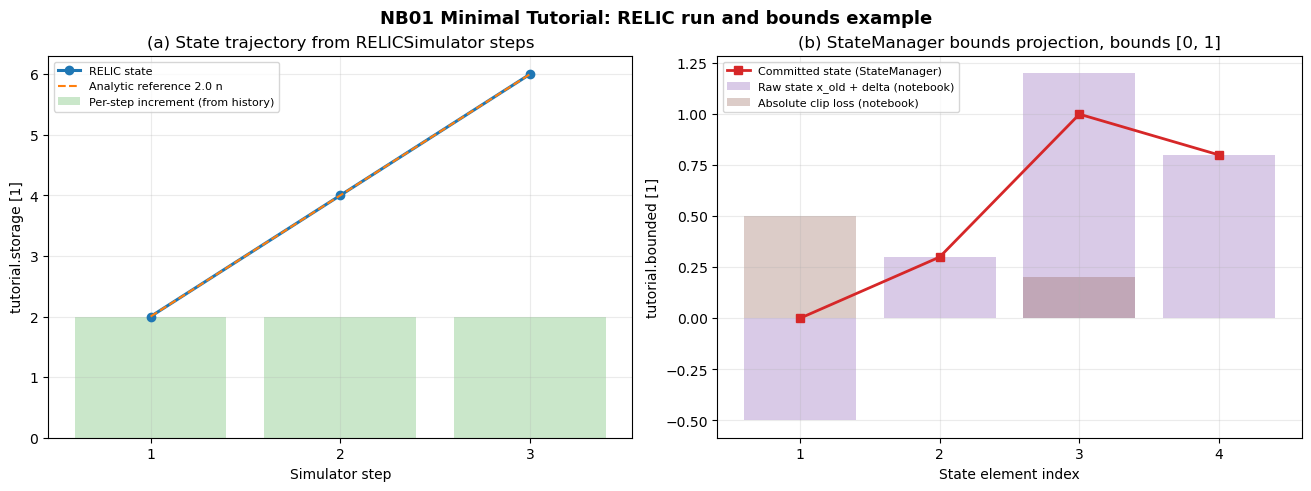

Summary:
  Final storage value (RELIC history): 6.00
  Mean increment per step (from the history): 2.00
  Total absolute clip loss (notebook, element-wise): 0.7000
  StateManager clip_loss record (signed sum): -0.3000
  Provenance entries (RELIC): 3
[OK] NB01 visualization drawn: RELIC history and committed state, plus the notebook-computed reference, increments, raw state and clip_loss.


In [5]:
# === Actual RELIC minimal-run visualization ===
# References:
#   - docs/source/architecture_overview.md, Section 4.4 (Simulator) and
#     Section 4.5 (State Management).
#   - docs/source/coertheory.md, Theorem 3.6.3.
# Mathematical expressions:
#   - storage_{n+1} = storage_n + increment
#   - reference_n = 2.0 * n (analytic reference, increment 2.0 per step)
#   - increment_n = storage_n - storage_{n-1}, with storage_0 = 0
#   - x_clipped = max(L, min(U, x_raw)); clip_loss = x_raw - x_clipped
# Parameter meanings:
#   - history: tutorial.storage read from StateManager after each RELICSimulator.step()
#   - increment: per-step change of tutorial.storage recovered from the history
#   - reference_n: analytic reference computed in this cell, not a RELIC output
#   - x_clipped: state committed by StateManager.apply_updates() in the bounds example
#   - x_raw = x_old + delta and the element-wise clip_loss = x_raw - x_clipped: computed
#     by the notebook; StateManager records only the signed sum (relic_clip_record)
# Units:
#   - tutorial.storage, reference_n, increment, x_raw, x_clipped and clip_loss are
#     dimensionless ("1"); n is the step number [1].
# Domain/constraints:
#   - history holds the three accepted steps of the run; the bounds example uses L = 0, U = 1.
# Sign convention:
#   - a positive increment increases storage; positive clip_loss removes storage and
#     negative clip_loss discloses storage added by the projection.

import matplotlib.pyplot as plt
import torch

step_tensor = torch.tensor([entry["step"] for entry in history], dtype=torch.float32)
storage_tensor = torch.tensor([entry["value"] for entry in history], dtype=torch.float32)
reference_tensor = 2.0 * step_tensor
increment_tensor = torch.diff(torch.cat([torch.tensor([0.0]), storage_tensor]))
clip_index_tensor = torch.arange(1, clip_loss.numel() + 1, dtype=torch.float32)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), constrained_layout=True)

axes[0].plot(step_tensor.tolist(), storage_tensor.tolist(), marker="o", linewidth=2.2, color="#1f77b4", label="RELIC state")
axes[0].plot(step_tensor.tolist(), reference_tensor.tolist(), linestyle="--", linewidth=1.5, color="#ff7f0e", label="Analytic reference 2.0 n")
axes[0].bar(step_tensor.tolist(), increment_tensor.tolist(), alpha=0.25, color="#2ca02c", label="Per-step increment (from history)")
axes[0].set_xlabel("Simulator step")
axes[0].set_ylabel("tutorial.storage [1]")
axes[0].set_title("(a) State trajectory from RELICSimulator steps")
axes[0].set_xticks(step_tensor.tolist())
axes[0].grid(True, alpha=0.25)
axes[0].legend(fontsize=8)

axes[1].bar(clip_index_tensor.tolist(), x_raw.tolist(), alpha=0.35, color="#9467bd", label="Raw state x_old + delta (notebook)")
axes[1].plot(clip_index_tensor.tolist(), x_clipped.tolist(), marker="s", linewidth=2.0, color="#d62728", label="Committed state (StateManager)")
axes[1].bar(clip_index_tensor.tolist(), clip_loss.abs().tolist(), alpha=0.30, color="#8c564b", label="Absolute clip loss (notebook)")
axes[1].set_xlabel("State element index")
axes[1].set_ylabel("tutorial.bounded [1]")
axes[1].set_title("(b) StateManager bounds projection, bounds [0, 1]")
axes[1].set_xticks(clip_index_tensor.tolist())
axes[1].grid(True, alpha=0.25)
axes[1].legend(fontsize=8)

plt.suptitle("NB01 Minimal Tutorial: RELIC run and bounds example", fontsize=13, fontweight="bold")
plt.show()

print("Summary:")
print(f"  Final storage value (RELIC history): {float(storage_tensor[-1]):.2f}")
print(f"  Mean increment per step (from the history): {float(torch.mean(increment_tensor)):.2f}")
print(f"  Total absolute clip loss (notebook, element-wise): {float(torch.sum(torch.abs(clip_loss))):.4f}")
print(f"  StateManager clip_loss record (signed sum): {relic_clip_record:.4f}")
print(f"  Provenance entries (RELIC): {len(provenance)}")
print("[OK] NB01 visualization drawn: RELIC history and committed state, plus the notebook-computed reference, increments, raw state and clip_loss.")


## Summary

The minimal run demonstrates the core RELIC lifecycle:
`BiologicalProcessFunctor` (a `FunctorBase` bridge) $\to$ `RELICSimulator.initialize_state()` (with declared units)
$\to$ `RELICSimulator.register_functor()` $\to$ `RELICSimulator.step()` $\to$ `StateManager.get_current_state()`.

In the stored run, three steps of `dt = 1.0` raise `tutorial.storage` from 0.0 to 6.0 (2.0 per step).
The bounds example shows that `StateManager.apply_updates()` projects a variable with declared bounds
onto [0, 1] and records the signed `clip_loss` sum (-0.3000 here).

**Next:** Proceed to **NB02** to explore real RELIC components and Functors.